# Symulator Epidemii — Monte Carlo
Ludzie ruszają się losowo po planszy 2D. Chorzy zarażają innych z prawdopodobieństwem `p_infect`.  

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

SEED = 67 #seed do losowania
N = 1500 #liczba ludzi
GRID = 140 #rozmiar planszy
N_STEPS = 200 #liczba dni
INIT_INFECTED = 15 #liczba osob ktore jest zakazonych w chwili poczatkowej
P_INFECT = 0.30 #prawd. zakazenia
P_RECOVER = 0.01 #prawd. wyzdrowienia
CONTACT_RADIUS = 1 #odleglosc na ktora moze nastapic zakazenie
RECOVERY_DELAY = 7 #czas aby byc gotowym do wyzdrowienia
HEALTHY, INFECTED, RECOVERED = range(3)
COLORS = ["#00FF00", "#FF0000", "#A425A6"]
LABELS = ["Zdrowy", "Chory", "Uzdrowiony"]

MOVES = np.array( [[-1, 0], [-1, 1], [0, 1], [1, 1], [1, 0], [1, -1], [0, -1], [-1, -1], [0, 0],],
                 dtype=int,)


# Pozycje i stany zdrowia ludzi
def init_sim(n=N, grid=GRID, init_infected=INIT_INFECTED, rng=None):
    rng = np.random.default_rng(SEED) if rng is None else rng
    positions = rng.integers(0, grid, (n, 2))
    status = np.full(n, HEALTHY, dtype=int)
    days_infected = np.full(n, -1, dtype=int)

    if init_infected > 0:
        # chcemy startowe zakazenia to losujemy osoby.
        init_infected = min(init_infected, n)
        idx = rng.choice(n, init_infected, replace=False)
        status[idx] = INFECTED
        days_infected[idx] = 0
    return positions, status, days_infected

# Jeden dzien symulacji:ruch, zakazenia, wyzdrowienia.
def step(pos, status, days_infected, rng, p_infect=P_INFECT, p_recover=P_RECOVER, contact_radius=CONTACT_RADIUS, recovery_delay=RECOVERY_DELAY, grid=GRID,):
    n = len(pos)
    move = MOVES[rng.integers(0, len(MOVES), n)]
    pos = (pos + move) % grid

    infected = np.where(status == INFECTED)[0]
    healthy = np.where(status == HEALTHY)[0]

    if infected.size:
        # Kazdy chory spedza kolejny dzien w chorobie.
        days_infected[infected] += 1
    if infected.size and healthy.size:
        # Liczymy, kto jest blisko chorych, i moze sie zarazic.
        diff = np.abs(pos[healthy][:, None] - pos[infected][None])
        close = np.max(diff, axis=2) <= contact_radius
        hits = close.sum(axis=1)
        if np.any(hits):
            # Jesli sa kontakty, losujemy nowe zakazenia.
            p = 1 - (1 - p_infect) ** hits
            new_inf = healthy[rng.random(healthy.size) < p]
            status[new_inf] = INFECTED
            days_infected[new_inf] = 0
    if infected.size:
        # Wyzdrowienia mozliwe dopiero po okresie opoznienia.
        ready = infected[days_infected[infected] >= recovery_delay]
        if ready.size:
            # Losujemy, kto z gotowych przypadkow ozdrowieje.
            recovered = ready[rng.random(ready.size) < p_recover]
            status[recovered] = RECOVERED
            days_infected[recovered] = -1
    return pos, status, days_infected


# Zlicza liczbe osob w kazdym stanie.
def count_states(status):
    return np.array([np.sum(status == HEALTHY),np.sum(status == INFECTED),np.sum(status == RECOVERED),])


# Uruchamia symulacje i zwraca przebieg oraz migawki.
def run(n=N, grid=GRID, p_infect=P_INFECT, p_recover=P_RECOVER, n_steps=N_STEPS, init_infected=INIT_INFECTED, contact_radius=CONTACT_RADIUS, recovery_delay=RECOVERY_DELAY, seed=SEED, snap_at=None,):
    rng = np.random.default_rng(seed)
    positions, status, days_infected = init_sim(n, grid, init_infected, rng)
    curves = np.zeros((n_steps, 3), dtype=int)
    snaps = {}
    snap_set = set(snap_at) if snap_at else None

    for t in range(n_steps):
        curves[t] = count_states(status)
        if snap_set and t in snap_set:
            # Zapisujemy wybrane momenty do podgladu.
            snaps[t] = (positions.copy(), status.copy())
        positions, status, days_infected = step(positions,status,days_infected,rng,p_infect,p_recover,contact_radius,recovery_delay,grid,)
    return curves, snaps


# Rysuje stan planszy dla wybranego momentu.
def plot_snapshot(positions, status, grid, ax, title=""):
    ax.set_facecolor("#1a1b3f")
    for state, color, label in zip([HEALTHY, INFECTED, RECOVERED], COLORS, LABELS):
        points = positions[status == state]
        if len(points) > 0:
            # Rysujemy osoby danego stanu jednym kolorem.
            ax.scatter(points[:, 0], points[:, 1], c=color, s=6, label=label, zorder=2)
    ax.set_xlim(-1, grid)
    ax.set_ylim(-1, grid)
    ax.set_aspect("equal")
    ax.set_title(title, color="white", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])



# Rysuje krzywa epidemii w czasie.
def plot_curve(curves, ax, title=""):
    t = np.arange(len(curves))
    ax.stackplot(t, curves[:, HEALTHY], curves[:, INFECTED], curves[:, RECOVERED], colors=COLORS, labels=LABELS, alpha=0.85,)
    ax.set_xlabel("Dzien")
    ax.set_ylabel("Liczba ludzi")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)
    ax.set_ylim(0, N)


## Eksperyment
Podgląd 4 momentów czasowych + krzywa epidemii.

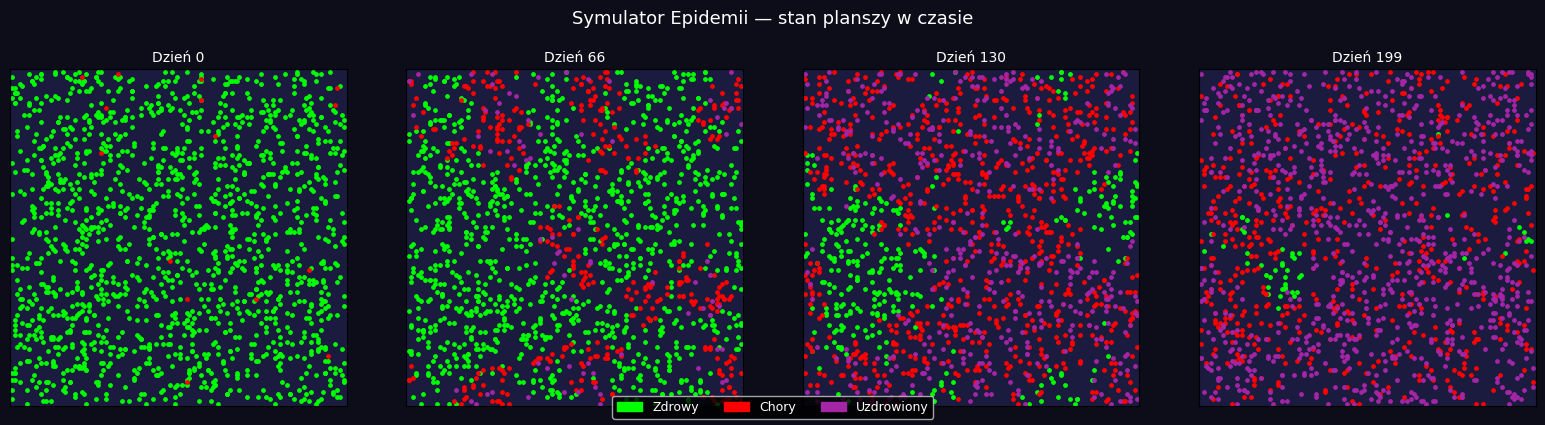

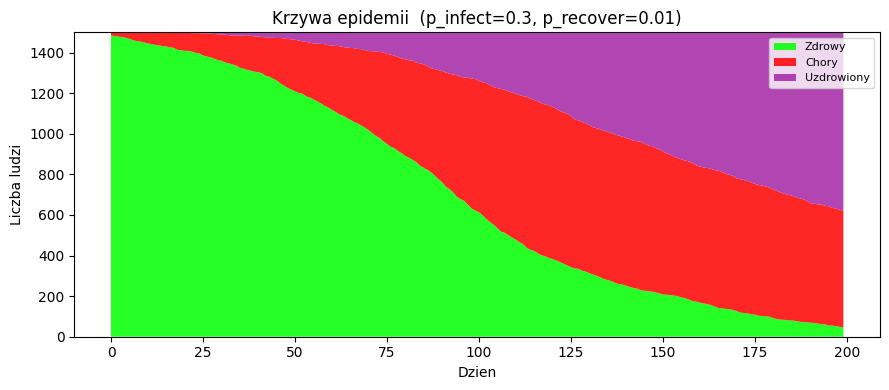

In [3]:
curves, snaps = run(snap_at={0, 66, 130, 199})

fig, axes = plt.subplots(1, 4, figsize=(16, 4), facecolor="#0d0d1a")
for ax, (t, (p, s)) in zip(axes, sorted(snaps.items())):
    plot_snapshot(p, s, GRID, ax, f"Dzień {t}")
handles = [mpatches.Patch(color=c, label=l) for c, l in zip(COLORS, LABELS)]
fig.legend(handles=handles, loc="lower center", ncol=4,
           facecolor="#000000", labelcolor="white", fontsize=9)
plt.suptitle("Symulator Epidemii — stan planszy w czasie", color="white", fontsize=13, y=1.03)
plt.tight_layout(); plt.show()

fig2, ax2 = plt.subplots(figsize=(9, 4))
plot_curve(curves, ax2, f"Krzywa epidemii  (p_infect={P_INFECT}, p_recover={P_RECOVER})")
plt.tight_layout(); plt.show()
